# 03 — Obfuskasiya olunmuş test dəsti

**Sual:** 99%+ nəticə göstərən detektorlar eyni hücumun obfuskasiya olunmuş formasını tanıyırmı?

- Modellər: `02_baseline_models_v2.ipynb`-də öyrədilmiş LR (əsas), Linear SVM, RF, Multinomial NB (`clean_v2`).
- Obfuskasiya yalnız **test dəstinin zərərli sorğularına** tətbiq olunur; train/val-a toxunulmur, modellər yenidən öyrədilmir.
- Texnikalar `src/obfuscation.py` modulundadır, hər biri ayrıca funksiyadır. Seed = 42.
- Texnika sorğunu dəyişmirsə (məs. sorğuda boşluq yoxdur), həmin sətir o texnikanın dəstindən çıxarılır.
- Hər texnika üçün recall həm obfuskasiyadan **əvvəl**, həm **sonra** eyni sətirlər üzərində hesablanır —
  beləliklə düşüş yalnız obfuskasiyanın təsirini göstərir, alt dəstin fərqli tərkibini yox.

## 0. Mühit, modellər və test dəsti

In [1]:
import random
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import obfuscation as obf

PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")

MODELS = {
    "LR": joblib.load(MODEL_DIR / "lr_v2.joblib"),
    "SVM": joblib.load(MODEL_DIR / "svm_v2.joblib"),
    "RF": joblib.load(MODEL_DIR / "rf_v2.joblib"),
    "NB": joblib.load(MODEL_DIR / "nb_v2.joblib"),
}
MODEL_COLORS = {"LR": "#2a78d6", "SVM": "#eb6834", "RF": "#1baf7a", "NB": "#eda100"}
lr = MODELS["LR"]

test = pd.read_csv(PROC_DIR / "test_v2.csv", keep_default_na=False, dtype={"Query": str, "Label": int})
malicious = test.loc[test.Label == 1, "Query"].reset_index(drop=True)
print(f"Test dəsti: {len(test)} sətir, zərərli: {len(malicious)}")

Test dəsti: 4539 sətir, zərərli: 1745


## 1. Texnikalar
`keyword_split_comment` (`UN/**/ION`) **MySQL-də sintaktik olaraq etibarsızdır**: şərh token ayırıcısı kimi işləyir,
`UN/**/ION` iki ayrı identifikator kimi oxunur və sorğu xəta verir. Bu texnika yalnız detektor testi üçündür —
real hücum kimi işləmir. Kombinasiyada bu texnika istifadə olunmur.

URL encoding texnikaları detektorun **dekodlanmamış** girişə baxdığı ssenarini modelləşdirir (məs. WAF xam HTTP
sorğusunu oxuyur). Express middleware-də parametrlər artıq dekodlanmış gəlir — bunu 5-ci mərhələdə nəzərə alacağıq.

In [2]:
DESCRIPTIONS = {
    "random_case": "Təsadüfi böyük-kiçik hərf: UnIoN SeLeCt",
    "inline_comment_space": "Boşluq → inline şərh: UNION/**/SELECT",
    "alt_whitespace": "Boşluq → tab / LF / CR / VT / FF (xam simvol)",
    "alt_whitespace_url": "Boşluq → %09 / %0a / %0d",
    "url_encode": "URL encoding: ' → %27",
    "double_url_encode": "İkiqat URL encoding: ' → %2527",
    "versioned_comment": "MySQL versiyalı şərh: /*!50000UNION*/",
    "logical_operator": "OR → ||, AND → &&",
    "hex_strings": "String literal → hex: 'admin' → 0x61646d696e",
    "keyword_split_comment": "Açar söz daxilində şərh: UN/**/ION (MySQL-də etibarsız)",
    "combination": "Təsadüfi 2–3 etibarlı texnika birlikdə",
}
TECH_ORDER = list(obf.TECHNIQUES) + ["combination"]
display(pd.DataFrame({
    "technique": TECH_ORDER,
    "description": [DESCRIPTIONS[t] for t in TECH_ORDER],
    "mysql_valid": [t not in obf.SYNTACTICALLY_INVALID for t in TECH_ORDER],
}))

,technique,description,mysql_valid
0,random_case,Təsadüfi böyük-kiçik hərf: UnIoN SeLeCt,True
1,inline_comment_space,Boşluq → inline şərh: UNION/**/SELECT,True
2,alt_whitespace,Boşluq → tab / LF / CR / VT / FF (xam simvol),True
3,alt_whitespace_url,Boşluq → %09 / %0a / %0d,True
4,url_encode,URL encoding: ' → %27,True
5,double_url_encode,İkiqat URL encoding: ' → %2527,True
6,versioned_comment,MySQL versiyalı şərh: /*!50000UNION*/,True
7,logical_operator,"OR → ||, AND → &&",True
8,hex_strings,String literal → hex: 'admin' → 0x61646d696e,True
9,keyword_split_comment,Açar söz daxilində şərh: UN/**/ION (MySQL-də e...,False


## 2. Obfuskasiyanın tətbiqi
Hər texnika bütün zərərli test sorğularına ayrıca tətbiq olunur. Dəyişməyən sətirlər çıxarılır;
neçə sətrin qaldığı aşağıdakı cədvəldədir. Bütün obfuskasiya olunmuş sorğular 4-cü mərhələdə (real MySQL testi)
istifadə üçün `data/processed/obfuscated_test_v2.csv` faylına yazılır.

In [3]:
frames = []
for tech in TECH_ORDER:
    rows = pd.DataFrame(obf.apply_technique(tech, malicious, seed=SEED))
    rows.insert(0, "technique", tech)
    frames.append(rows)
all_rows = pd.concat(frames, ignore_index=True)

coverage = all_rows.groupby("technique", sort=False).agg(total=("changed", "size"), kept=("changed", "sum"))
coverage["dropped"] = coverage["total"] - coverage["kept"]
coverage["kept_pct"] = (coverage["kept"] / coverage["total"] * 100).round(1)
display(coverage)

obf_df = all_rows[all_rows.changed].drop(columns="changed").reset_index(drop=True)
obf_df["mysql_valid"] = ~obf_df["technique"].isin(obf.SYNTACTICALLY_INVALID)
obf_df.to_csv(PROC_DIR / "obfuscated_test_v2.csv", index=False, encoding="utf-8")
print(f"obfuscated_test_v2.csv: {len(obf_df)} sətir")

print("\nKombinasiyada istifadə olunan texnika dəstləri (ən çox 10):")
display(obf_df.loc[obf_df.technique == "combination", "techniques"].value_counts().head(10))

,total,kept,dropped,kept_pct
technique,,,,
random_case,1745,1714,31,98.2
inline_comment_space,1745,1732,13,99.3
alt_whitespace,1745,1732,13,99.3
alt_whitespace_url,1745,1732,13,99.3
url_encode,1745,1740,5,99.7
double_url_encode,1745,1740,5,99.7
versioned_comment,1745,1714,31,98.2
logical_operator,1745,1070,675,61.3
hex_strings,1745,628,1117,36.0


obfuscated_test_v2.csv: 17155 sətir

Kombinasiyada istifadə olunan texnika dəstləri (ən çox 10):


techniques
hex_strings+versioned_comment                     65
hex_strings+random_case                           65
logical_operator+versioned_comment                53
logical_operator+random_case                      53
random_case+versioned_comment                     50
logical_operator+hex_strings                      49
versioned_comment+alt_whitespace                  43
logical_operator+alt_whitespace                   42
logical_operator+hex_strings+versioned_comment    42
logical_operator+hex_strings+random_case          39
Name: count, dtype: int64

## 3. Qiymətləndirmə: hər texnika üzrə recall
Bütün sətirlər zərərli olduğundan, recall = aşkarlanan sorğuların payı. Hər texnika üçün:
- `recall_before` — həmin sətirlərin **orijinal** formasında recall
- `recall_after` — obfuskasiyadan sonra recall
- `drop` = before − after (faiz bəndi)

LR üçün əlavə olaraq orta ehtimal (əvvəl/sonra) göstərilir. Hədd = 0.5.

In [4]:
pred_orig = {m: model.predict(malicious) for m, model in MODELS.items()}
p_orig_lr = lr.predict_proba(malicious)[:, 1]

result_rows = []
for m, model in MODELS.items():
    result_rows.append({"technique": "original", "model": m, "n_rows": len(malicious), "mysql_valid": True,
                        "recall_before": pred_orig[m].mean(), "recall_after": pred_orig[m].mean()})

obf_df["p_lr_before"] = p_orig_lr[obf_df["index"]]
obf_df["p_lr_after"] = lr.predict_proba(obf_df["obfuscated"])[:, 1]
for m, model in MODELS.items():
    obf_df[f"pred_{m}"] = model.predict(obf_df["obfuscated"])

for tech in TECH_ORDER:
    sub = obf_df[obf_df.technique == tech]
    for m in MODELS:
        result_rows.append({
            "technique": tech, "model": m, "n_rows": len(sub),
            "mysql_valid": tech not in obf.SYNTACTICALLY_INVALID,
            "recall_before": pred_orig[m][sub["index"]].mean(),
            "recall_after": sub[f"pred_{m}"].mean(),
        })

results = pd.DataFrame(result_rows)
results["drop_pp"] = (results["recall_before"] - results["recall_after"]) * 100
lr_prob = obf_df.groupby("technique")[["p_lr_before", "p_lr_after"]].mean()
results = results.merge(lr_prob.rename(columns={"p_lr_before": "lr_mean_p_before", "p_lr_after": "lr_mean_p_after"}),
                        left_on="technique", right_index=True, how="left")
results.loc[results.model != "LR", ["lr_mean_p_before", "lr_mean_p_after"]] = np.nan
for c in ["recall_before", "recall_after", "lr_mean_p_before", "lr_mean_p_after"]:
    results[c] = results[c].round(4)
results["drop_pp"] = results["drop_pp"].round(2)
results.to_csv(RES_DIR / "obfuscation_results.csv", index=False)

recall_table = results.pivot(index="technique", columns="model", values="recall_after")[list(MODELS)]
recall_table = recall_table.loc[["original"] + TECH_ORDER]
recall_table.insert(0, "n_rows", results.drop_duplicates("technique").set_index("technique")["n_rows"])
recall_table.insert(1, "mysql_valid", [t not in obf.SYNTACTICALLY_INVALID for t in recall_table.index])
recall_table["LR_drop_pp"] = results[results.model == "LR"].set_index("technique")["drop_pp"]
recall_table["LR_mean_p_after"] = results[results.model == "LR"].set_index("technique")["lr_mean_p_after"]
recall_table.to_csv(RES_DIR / "obfuscation_recall_table.csv")
pd.set_option("display.width", 200)
display((recall_table.style.format({m: "{:.2%}" for m in MODELS} | {"LR_drop_pp": "{:.2f}", "LR_mean_p_after": "{:.3f}"})))

model,n_rows,mysql_valid,LR,SVM,RF,NB,LR_drop_pp,LR_mean_p_after
technique,,,,,,,,
original,1745,True,99.60%,99.60%,99.31%,98.91%,0.00,nan
random_case,1714,True,100.00%,100.00%,99.71%,99.47%,0.00,0.998
inline_comment_space,1732,True,100.00%,100.00%,38.39%,99.83%,0.00,0.991
alt_whitespace,1732,True,77.77%,68.36%,33.20%,98.27%,22.23,0.750
alt_whitespace_url,1732,True,76.39%,40.36%,46.36%,74.19%,23.61,0.704
url_encode,1740,True,98.39%,78.51%,4.31%,98.97%,1.49,0.850
double_url_encode,1740,True,39.94%,9.14%,0.17%,98.51%,59.94,0.461
versioned_comment,1714,True,100.00%,100.00%,95.51%,99.59%,0.00,0.999
logical_operator,1070,True,100.00%,100.00%,99.63%,99.63%,0.00,0.999


## 4. Qruplaşdırılmış bar chart
Hər texnika üçün dörd modelin recall-u (obfuskasiyadan sonra). Texnikalar LR recall-una görə sıralanıb;
ən üstdə orijinal (obfuskasiyasız) test dəsti. `†` — MySQL-də sintaktik olaraq etibarsız.

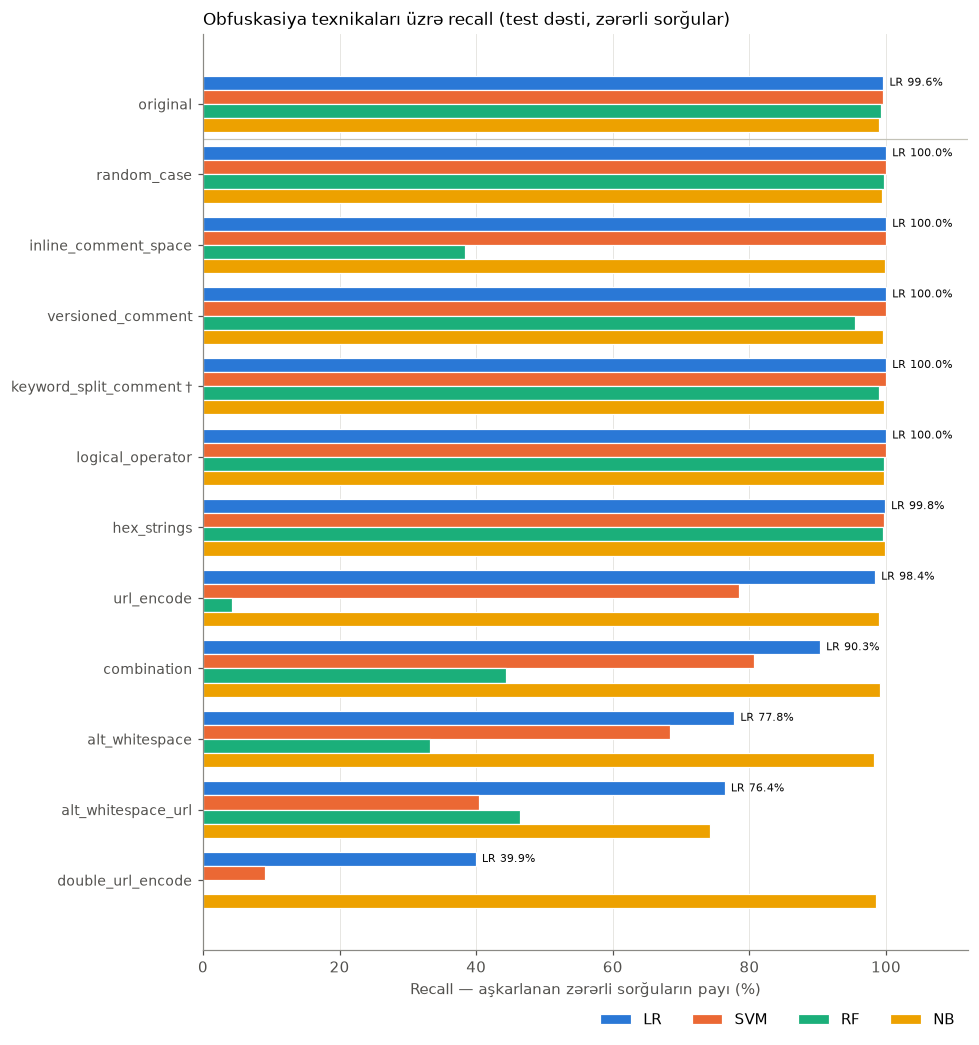

In [5]:
order = ["original"] + recall_table.drop(index="original").sort_values("LR", ascending=False).index.tolist()
labels = [t + (" †" if t in obf.SYNTACTICALLY_INVALID else "") for t in order]
y = np.arange(len(order))[::-1]
h = 0.2
fig, ax = plt.subplots(figsize=(9, 9.5))
for k, m in enumerate(MODELS):
    vals = recall_table.loc[order, m].to_numpy() * 100
    ax.barh(y + (1.5 - k) * h, vals, height=h, color=MODEL_COLORS[m], label=m, edgecolor="white", linewidth=0.8)
for yi, t in zip(y, order):
    v = recall_table.loc[t, "LR"] * 100
    ax.annotate(f"LR {v:.1f}%", (v, yi + 1.5 * h), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=7.5, color="#0b0b0b")
ax.set_yticks(y, labels, fontsize=9)
ax.set_xlim(0, 112)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Recall — aşkarlanan zərərli sorğuların payı (%)")
ax.set_title("Obfuskasiya texnikaları üzrə recall (test dəsti, zərərli sorğular)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
ax.axhline(y[0] - 0.5, color="#c3c2b7", linewidth=0.8)
ax.legend(frameon=False, loc="lower right", ncol=4, bbox_to_anchor=(1, -0.1))
fig.tight_layout()
save_fig(fig, "03_obfuscation_recall.png")
plt.show()

## 5. Hər texnikadan nümunə
Hər texnika üçün bir təsadüfi sətir (seed = 42): orijinal sorğu, obfuskasiya olunmuş forma və LR-in
zərərli olma ehtimalı əvvəl → sonra.

In [6]:
examples = (obf_df.groupby("technique", sort=False).sample(1, random_state=SEED)
            .set_index("technique").loc[TECH_ORDER].reset_index())
examples[["technique", "techniques", "original", "obfuscated", "p_lr_before", "p_lr_after"]].to_csv(
    RES_DIR / "03_examples.csv", index=False)
for _, r in examples.iterrows():
    extra = f"  [{r.techniques}]" if r.technique == "combination" else ""
    print(f"== {r.technique}{extra}")
    print(f"   orijinal : {r.original[:150]!r}")
    print(f"   obfusk.  : {r.obfuscated[:150]!r}")
    print(f"   LR p     : {r.p_lr_before:.3f} → {r.p_lr_after:.3f}")

== random_case
   orijinal : '-3960"   )    )    union all select 7813,7813,7813,7813,7813,7813--'
   obfusk.  : '-3960"   )    )    Union aLl SeLEcT 7813,7813,7813,7813,7813,7813--'
   LR p     : 0.999 → 0.999
== inline_comment_space
   orijinal : "1'||  (  select 'dfmw' from dual where 1723  =  1723"
   obfusk.  : "1'||/**/(/**/select/**/'dfmw'/**/from/**/dual/**/where/**/1723/**/=/**/1723"
   LR p     : 0.996 → 0.981
== alt_whitespace
   orijinal : "-7238%' or make_set  (  5375  =  9563,9563  )   and '%'  =  '"
   obfusk.  : "-7238%'\nor\x0cmake_set\x0c(\x0c5375\t=\n9563,9563\n)\x0cand\x0b'%'\x0b=\x0b'"
   LR p     : 1.000 → 0.896
== alt_whitespace_url
   orijinal : '1   )    )    as rbcf where 1053  =  1053'
   obfusk.  : '1%0a)%0a)%09as%09rbcf%0awhere%0a1053%0d=%091053'
   LR p     : 0.996 → 0.062
== url_encode
   orijinal : "-7209'   )    )     )   or 3440  =  cast   (    (   chr  (  113  )  ||chr  (  113  )  ||chr  (  112  )  ||chr  (  106  )  ||chr  (  113   )    )   || "
   ob

## 6. Recall-u ən çox düşən 3 texnika: hansı n-gram-lar itir?
LR xətti modeldir, ona görə qərar `logit = Σ tfidf(n-gram) · w(n-gram) + b` kimi parçalanır.
Hər n-gram üçün orijinal və obfuskasiya olunmuş sorğulardakı **töhfəni** (tfidf · w) müqayisə edirik
(texnikanın bütün sətirləri üzrə orta):
- **itən zərərli siqnal** — müsbət çəkili (zərərli) n-gram-lar, obfuskasiyadan sonra azalıb/yox olub
- **yaranan təmiz siqnal** — mənfi çəkili (təmiz) n-gram-lar, obfuskasiyadan sonra yaranıb/artıb

Qeyd: TF-IDF vektorlaşdırıcısı `lowercase=True` ilə öyrədildiyi üçün `random_case` modelə heç bir təsir göstərmir
(sorğular əvvəlcə kiçik hərfə çevrilir).

In [7]:
vec = lr.named_steps["tfidf"]
w = lr.named_steps["clf"].coef_[0]
vocab = np.array(vec.get_feature_names_out())

top3 = (results[(results.model == "LR") & (results.technique != "original")]
        .sort_values("drop_pp", ascending=False).head(3)["technique"].tolist())
print("Recall-u ən çox düşən 3 texnika (LR):", top3)

loss_tables = {}
for tech in top3:
    sub = obf_df[obf_df.technique == tech]
    Xo = vec.transform(sub["original"])
    Xa = vec.transform(sub["obfuscated"])
    contrib_o = np.asarray(Xo.mean(axis=0)).ravel() * w
    contrib_a = np.asarray(Xa.mean(axis=0)).ravel() * w
    delta = contrib_o - contrib_a  # > 0: logit bu n-gram hesabına azalıb
    t = pd.DataFrame({"ngram": vocab, "weight": w, "contrib_before": contrib_o,
                      "contrib_after": contrib_a, "logit_loss": delta})
    lost = t[(t.weight > 0) & (t.logit_loss > 0)].nlargest(12, "logit_loss").assign(kind="itən zərərli siqnal")
    gained = t[(t.weight < 0) & (t.logit_loss > 0)].nlargest(8, "logit_loss").assign(kind="yaranan təmiz siqnal")
    tab = pd.concat([lost, gained])
    tab.to_csv(RES_DIR / f"03_ngram_loss_{tech}.csv", index=False)
    loss_tables[tech] = tab

    logit_o = lr.decision_function(sub["original"]).mean()
    logit_a = lr.decision_function(sub["obfuscated"]).mean()
    print(f"\n===== {tech}: orta logit {logit_o:+.2f} → {logit_a:+.2f} =====")
    show = tab[["kind", "ngram", "weight", "contrib_before", "contrib_after", "logit_loss"]].copy()
    show["ngram"] = show["ngram"].map(repr)
    display(show.round(4))

Recall-u ən çox düşən 3 texnika (LR): ['double_url_encode', 'alt_whitespace_url', 'alt_whitespace']



===== double_url_encode: orta logit +11.57 → -0.17 =====


,kind,ngram,weight,contrib_before,contrib_after,logit_loss
0,itən zərərli siqnal,' ',12.182000,0.6477,0.0000,0.6477
10141,itən zərərli siqnal,"""'""",12.621300,0.2855,0.0000,0.2855
5131,itən zərərli siqnal,' =',10.899700,0.2570,0.0000,0.2570
5132,itən zərərli siqnal,' = ',10.899700,0.2570,0.0000,0.2570
34677,itən zərərli siqnal,'=',10.899700,0.2570,0.0000,0.2570
34678,itən zərərli siqnal,'= ',10.899700,0.2570,0.0000,0.2570
2126,itən zərərli siqnal,' )',6.833300,0.2312,0.0000,0.2312
2127,itən zərərli siqnal,' ) ',6.833300,0.2312,0.0000,0.2312
14186,itən zərərli siqnal,')',6.833300,0.2312,0.0000,0.2312
14187,itən zərərli siqnal,') ',6.833300,0.2312,0.0000,0.2312



===== alt_whitespace_url: orta logit +11.62 → +1.53 =====


,kind,ngram,weight,contrib_before,contrib_after,logit_loss
0,itən zərərli siqnal,' ',12.1820,0.6507,0.0000,0.6507
5131,itən zərərli siqnal,' =',10.8997,0.2582,0.0000,0.2582
5132,itən zərərli siqnal,' = ',10.8997,0.2582,0.0000,0.2582
34678,itən zərərli siqnal,'= ',10.8997,0.2582,0.0000,0.2582
2126,itən zərərli siqnal,' )',6.8333,0.2323,0.0000,0.2323
2127,itən zərərli siqnal,' ) ',6.8333,0.2323,0.0000,0.2323
14187,itən zərərli siqnal,') ',6.8333,0.2323,0.0000,0.2323
2134,itən zərərli siqnal,' ) )',7.0752,0.1551,0.0000,0.1551
2135,itən zərərli siqnal,' ) ) ',7.0752,0.1551,0.0000,0.1551
14213,itən zərərli siqnal,') )',7.0752,0.1551,0.0000,0.1551



===== alt_whitespace: orta logit +11.62 → +2.58 =====


,kind,ngram,weight,contrib_before,contrib_after,logit_loss
0,itən zərərli siqnal,' ',12.1820,0.6507,0.0000,0.6507
5131,itən zərərli siqnal,' =',10.8997,0.2582,0.0000,0.2582
5132,itən zərərli siqnal,' = ',10.8997,0.2582,0.0000,0.2582
34678,itən zərərli siqnal,'= ',10.8997,0.2582,0.0000,0.2582
2126,itən zərərli siqnal,' )',6.8333,0.2323,0.0000,0.2323
2127,itən zərərli siqnal,' ) ',6.8333,0.2323,0.0000,0.2323
14187,itən zərərli siqnal,') ',6.8333,0.2323,0.0000,0.2323
2134,itən zərərli siqnal,' ) )',7.0752,0.1551,0.0000,0.1551
2135,itən zərərli siqnal,' ) ) ',7.0752,0.1551,0.0000,0.1551
14213,itən zərərli siqnal,') )',7.0752,0.1551,0.0000,0.1551


Ən çox düşən 3 texnika üçün itən zərərli n-gram-ların vizual müqayisəsi (orta logit itkisi).

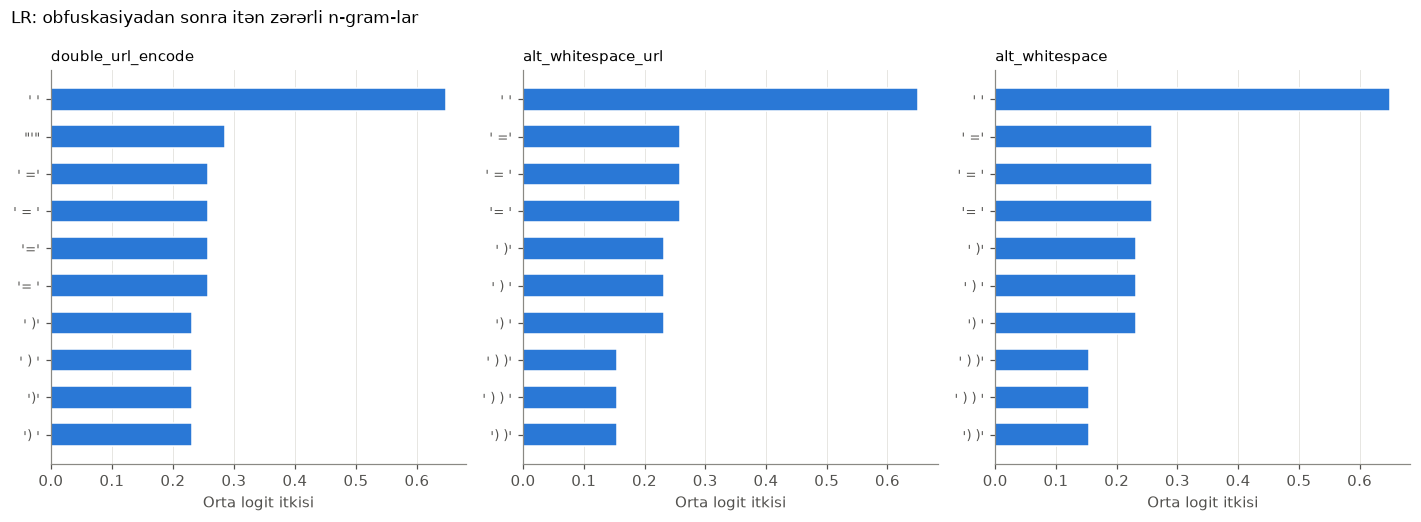

In [8]:
fig, axes = plt.subplots(1, len(top3), figsize=(13, 4.8))
for ax, tech in zip(np.atleast_1d(axes), top3):
    t = loss_tables[tech]
    t = t[t.kind == "itən zərərli siqnal"].head(10).iloc[::-1]
    ax.barh([repr(s) for s in t["ngram"]], t["logit_loss"], color="#2a78d6", height=0.6,
            edgecolor="white", linewidth=1)
    ax.set_title(tech, loc="left", fontsize=10)
    ax.set_xlabel("Orta logit itkisi")
    ax.tick_params(axis="y", labelsize=8.5)
    ax.grid(axis="y", visible=False)
fig.suptitle("LR: obfuskasiyadan sonra itən zərərli n-gram-lar", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
save_fig(fig, "03_ngram_loss_top3.png")
plt.show()